TokaMaker Example: TCS FRC equilibrium {#doc_tMaker_TCS_ex2}
==========
In this example we demonstrate how to create a field-reversed configuration (FRC) equilibrium for the Translation, Confinement, and Sustainment (TCS) experiment [[A. L. Hoffman et al. (2002)](https://doi.org/10.13182/FST02-A205)].

This example utilizes the mesh built in \ref doc_tMaker_TCS_ex1.

**Note:** Running this example requires the [h5py](https://www.h5py.org/) python package, which is installable using `pip` or other standard methods.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(6,6)
plt.rcParams['font.weight']='bold'
plt.rcParams['axes.labelweight']='bold'
plt.rcParams['lines.linewidth']=2
plt.rcParams['lines.markeredgewidth']=2
%matplotlib inline
%config InlineBackend.figure_format = "retina"

## Load TokaMaker library

To load the TokaMaker python module we need to tell python where to the module is located. This can be done either through the `PYTHONPATH` environment variable or using within a script using `sys.path.append()` as below, where we look for the environement variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed (`/Applications/OFT` on macOS).

In [2]:
tokamaker_python_path = os.getenv('OFT_ROOTPATH')
if tokamaker_python_path is not None:
    sys.path.append(os.path.join(tokamaker_python_path,'python'))
from OpenFUSIONToolkit import OFT_env
from OpenFUSIONToolkit.TokaMaker import TokaMaker
from OpenFUSIONToolkit.TokaMaker.meshing import load_gs_mesh

## Setup calculation

### Initialize TokaMaker object
We now create a \ref OpenFUSIONToolkit.OFT_env "OFT_env" instance for execution using four threads and a \ref OpenFUSIONToolkit.TokaMaker.TokaMaker "TokaMaker" instance to use for equilibrium calculations.

In [3]:
myOFT = OFT_env(nthreads=4)
mygs = TokaMaker(myOFT)

#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/



Base release:        v26.9
Development branch:  claude/tokamaker-solovev-example-8c907d
Revision id:         9bbca10f

Parallelization Info:
  # of MPI tasks      =    1
  # of NUMA nodes     =    1
  # of OpenMP threads =    4

Linear Algebra backend: native

#----------------------------------------------



### Load mesh into TokaMaker
Now we load the mesh generated in \ref doc_tMaker_TCS_ex1 using \ref OpenFUSIONToolkit.TokaMaker.load_gs_mesh "load_gs_mesh()" and \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.setup_mesh "setup_mesh". Then we use \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.setup_regions "setup_regions()", passing the conductor and coil dictionaries for the mesh, to define the different region types. Finally, we call \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.setup "setup()" to setup the required solver objects. During this call we can specify the desired element order (min=2, max=4).

In [4]:
mesh_pts,mesh_lc,mesh_reg,coil_dict,cond_dict = load_gs_mesh('TCS_mesh.h5')
mygs.setup_mesh(mesh_pts, mesh_lc, mesh_reg)
mygs.setup_regions(cond_dict=cond_dict,coil_dict=coil_dict)
mygs.setup(order=2)


**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  3.200E+00
    # of points  =   10896
    # of edges   =   32347
    # of cells   =   21452
    # of boundary points =     338
    # of boundary edges  =     338
    # of boundary cells  =     338
  Resolution statistics:
    hmin =  6.250E-03
    hrms =  1.969E-02
    hmax =  7.413E-02
  Surface grounded at vertex     943


**** Creating Lagrange FE space
  Order  =    2
  Minlev =   -1

 Computing flux BC matrix 


 Inverting real matrix
   Time =    1.1674000000000000E-002


### Solve for vacuum field
Each coil in the TCS mesh is an independent coil. However, for the initial vacuum (bias) field we want a uniform current in all of the coils in each of the three coil groups (`CENTRAL`, `END`, and `MIRROR`). We first build a list of the coils in each group using the coil names.

In [5]:
coil_groups = {}
for coil_name in coil_dict:
    group_name = coil_name.rstrip('0123456789')
    coil_groups.setdefault(group_name,[]).append(coil_name)
for group_name, coil_names in coil_groups.items():
    print('{0:8} {1}'.format(group_name,', '.join(coil_names)))

END      END1, END2, END3, END18, END19, END20
CENTRAL  CENTRAL4, CENTRAL5, CENTRAL6, CENTRAL7, CENTRAL8, CENTRAL9, CENTRAL10, CENTRAL11, CENTRAL12, CENTRAL13, CENTRAL14, CENTRAL15, CENTRAL16, CENTRAL17
MIRROR   MIRROR1, MIRROR2


We now choose the current in each group to give a target axial field ($B_z$) at several points along the geometric axis:
 - $B_z = 0.10$ T at $Z = 0$ (midplane)
 - $B_z = 0.12$ T at $Z = \pm 1.0$ m (end coils)
 - $B_z = 0.20$ T at $Z = \pm 1.45$ m (cone mirror coils)

As the vacuum field is linear in the coil currents we can find the required currents by computing the field from a unit current (1 A in each coil of a group) for each group using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.vac_solve "vac_solve()". This gives a response matrix relating the group currents to the field at each target point, which we then invert in a least-squares sense.

**Note:** The field is evaluated slightly off axis ($R = 1$ mm) to avoid the coordinate singularity at $R = 0$.

In [6]:
# Target axial field at points along the axis
target_z = np.r_[0.0, -1.0, 1.0, -1.45, 1.45]
target_Bz = np.r_[0.10, 0.12, 0.12, 0.20, 0.20]
eval_r = 1.E-3

# Compute field response to unit current in each group
group_names = list(coil_groups.keys())
Bz_resp = np.zeros((target_z.shape[0],len(group_names)))
for j, group_name in enumerate(group_names):
    mygs.set_coil_currents({coil_name: 1.0 for coil_name in coil_groups[group_name]})
    EQ_unit = mygs.vac_solve()
    mygs.set_psi(EQ_unit.get_psi(False))
    field_eval = mygs.get_field_eval('B')
    for i, z in enumerate(target_z):
        Bz_resp[i,j] = field_eval.eval(np.r_[eval_r,z])[2]

# Solve for group currents
group_currents = np.linalg.lstsq(Bz_resp,target_Bz,rcond=None)[0]
for group_name, current in zip(group_names,group_currents):
    print('I_{0:8} = {1:8.2f} [A] ({2:6.2f} [kA-turns/coil])'.format(group_name,current,current*coil_dict[coil_groups[group_name][0]]['nturns']/1.E3))

   1  2.6790E-06
   1  1.6638E-05
   1  6.2105E-07
I_END      =   219.07 [A] ( 12.27 [kA-turns/coil])
I_CENTRAL  =   186.52 [A] ( 10.45 [kA-turns/coil])
I_MIRROR   =   740.04 [A] ( 89.54 [kA-turns/coil])


Finally, we set the resulting currents in all of the coils, compute the corresponding vacuum field, and compare the field at each of the target points.

In [7]:
# Set coil currents and solve for vacuum field
coil_currents = {}
for group_name, current in zip(group_names,group_currents):
    for coil_name in coil_groups[group_name]:
        coil_currents[coil_name] = current
mygs.set_coil_currents(coil_currents)
EQ_vac = mygs.vac_solve()
psi_vac = EQ_vac.get_psi(False)

# Get B-field at target points
mygs.set_psi(psi_vac)
field_eval = mygs.get_field_eval('B')
for z, Bz_target in zip(target_z,target_Bz):
    B = field_eval.eval(np.r_[eval_r,z])
    print('B_z(Z = {0:5.2f}) = {1:6.3f} [T] (target: {2:5.3f})'.format(z,B[2],Bz_target))

   1  1.7724E+00
B_z(Z =  0.00) =  0.100 [T] (target: 0.100)
B_z(Z = -1.00) =  0.120 [T] (target: 0.120)
B_z(Z =  1.00) =  0.120 [T] (target: 0.120)
B_z(Z = -1.45) =  0.200 [T] (target: 0.200)
B_z(Z =  1.45) =  0.200 [T] (target: 0.200)


We now plot the resulting vacuum flux surfaces along with the current in each coil, as well as the axial field along the geometric axis within the plasma region.

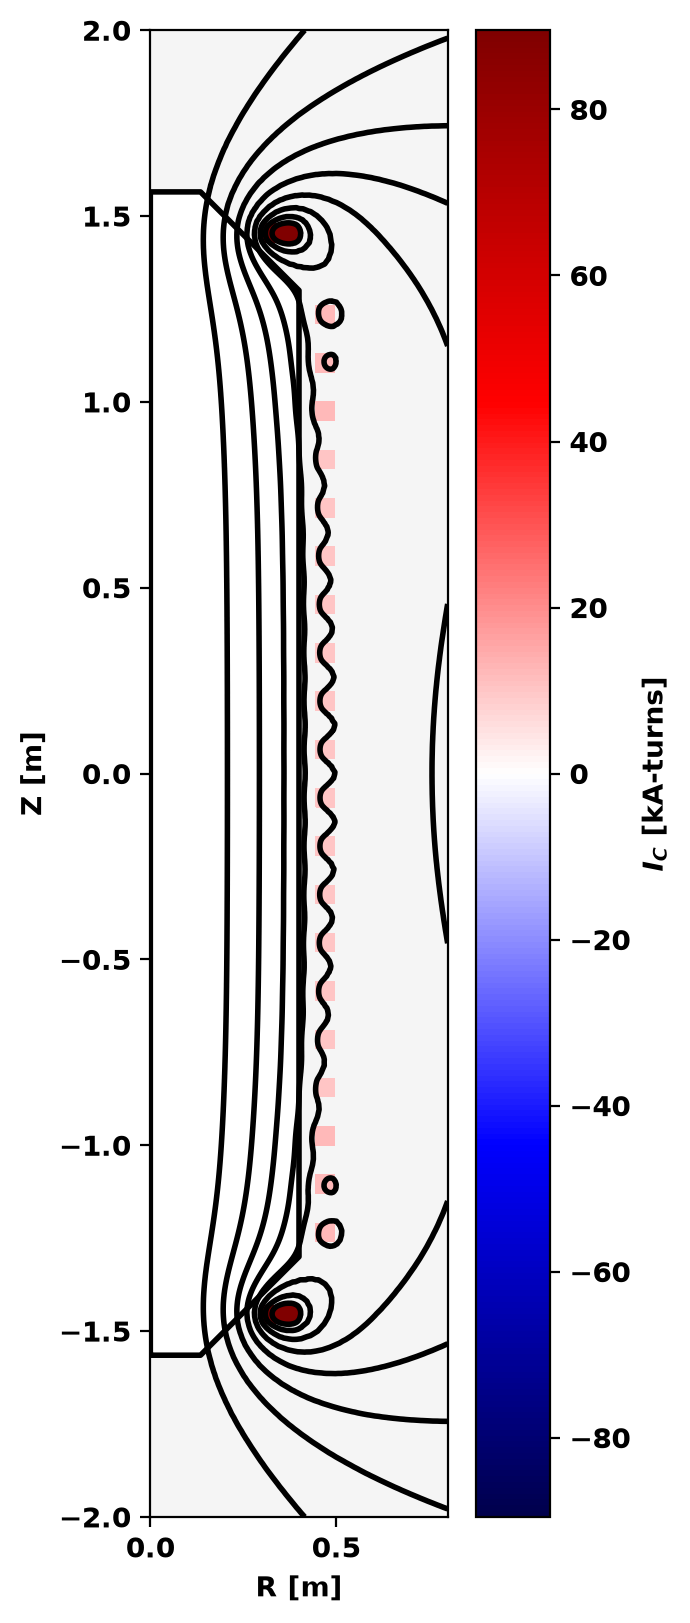

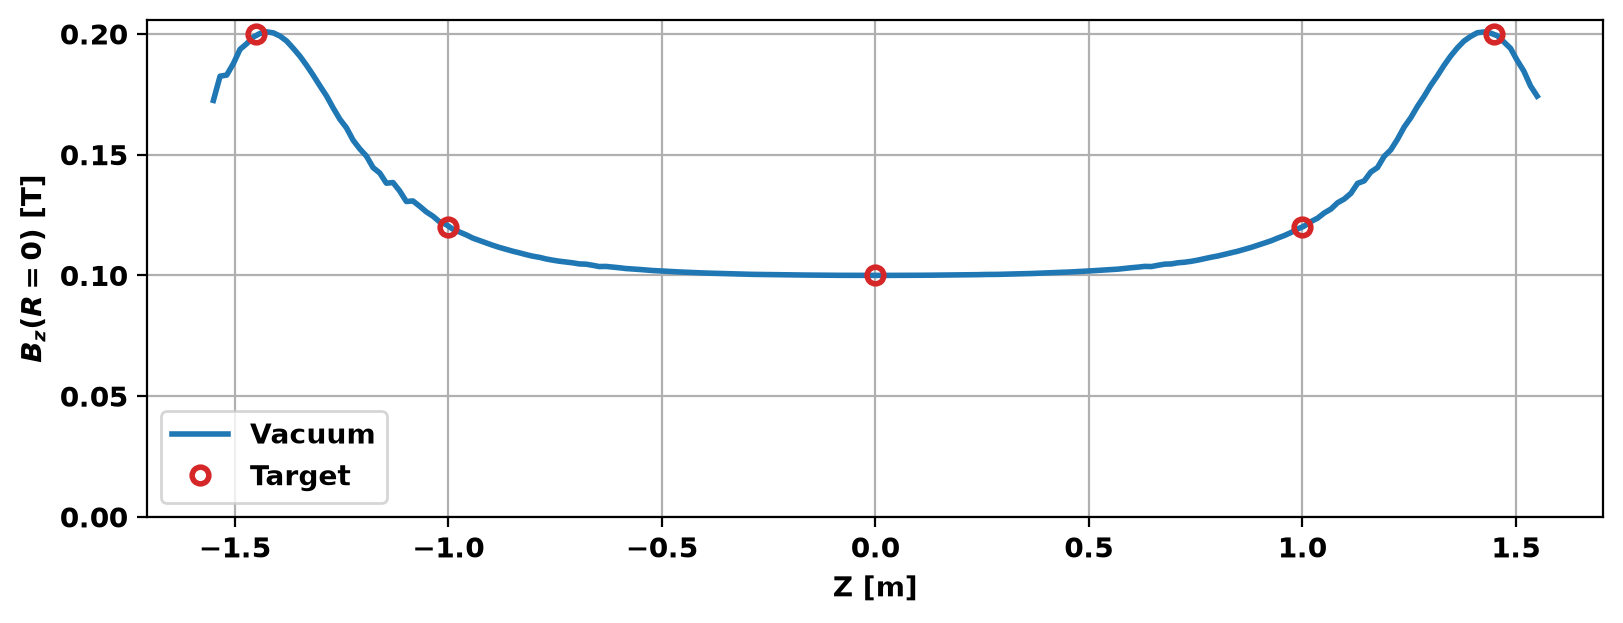

In [8]:
# Plot flux surfaces
fig, ax = plt.subplots(1,1,figsize=(4,8),constrained_layout=True)
mygs.plot_machine(fig,ax,coil_colormap='seismic',coil_symmap=True,coil_scale=1.E-3,coil_clabel=r'$I_C$ [kA-turns]')
mygs.plot_psi(fig,ax,psi=psi_vac,normalized=False,plasma_nlevels=10,plasma_color='k',vacuum_nlevels=0,xpoint_color=None,opoint_color=None)
ax.set_xlabel('R [m]')
ax.set_ylabel('Z [m]')

# Plot axial field on axis
z_axis = np.linspace(-1.55,1.55,200)
Bz_axis = np.zeros(z_axis.shape)
for i, z in enumerate(z_axis):
    Bz_axis[i] = field_eval.eval(np.r_[eval_r,z])[2]
fig, ax = plt.subplots(1,1,figsize=(8,3),constrained_layout=True)
ax.plot(z_axis,Bz_axis,label='Vacuum')
ax.plot(target_z,target_Bz,'o',color='tab:red',fillstyle='none',label='Target')
ax.set_ylim(bottom=0.0)
ax.grid(True)
ax.legend()
ax.set_xlabel('Z [m]')
_ = ax.set_ylabel(r'$B_z(R=0)$ [T]')